In [10]:
from debugpy.server.cli import TARGET
from sklearn.model_selection import train_test_split

from autogluon.tabular import TabularDataset, TabularPredictor
from autogluon.features.generators import AutoMLPipelineFeatureGenerator

import seaborn as sns
import matplotlib.pyplot as plt




In [11]:
TARGET = 'Golongan UKT'
ID = 'id'
COl_TO_DROP = ["Golongan UKT",'id',"Lokasi Tempat Tinggal", 'Total Hutang', 'Status Kepemilikan Tempat Tinggal' ]
DROP = [TARGET, ID]
SEED = 42
N_SPLITS = 5

In [12]:
import pandas as pd

train = pd.read_csv('train.csv')

train.head()

,id,Pendapatan Keluarga,Jumlah Tanggungan dalam Keluarga,Pekerjaan Orang Tua/Wali,Pendidikan Orang Tua/Wali,Kepemilikan Aset,Lokasi Tempat Tinggal,Pengeluaran Bulanan Keluarga,Status Kepesertaan Program Bantuan Pemerintah,Riwayat Beasiswa atau Bantuan Pendidikan,...,Bahan Atap Rumah,Bahan Tembok Rumah,Bahan Lantai Rumah,Rerata Pengeluaran Listrik & Air per Bulan,Total Hutang,Cicilan Hutang per Bulan,Program Studi,Kota,Jalur Masuk,Golongan UKT
0,127748,Rp 1.000.000 s.d. Rp 2.000.000,2.0,Tidak Bekerja,SLTA Sederajat,Milik Sendiri,Kab. Sragen,500000.0,KIS/JKS/BPJS,KIPK,...,genting,semen,keramik,450000.0,0.0,0.0,Ilmu Politik,Kab. Sragen,SNBT,0.0
1,90205,lebih dari Rp 5.000.000,2.0,Buruh,SLTA Sederajat,Milik Sendiri,Kabupaten Tangerang,3500000.0,KIS/JKS/BPJS,Tidak Ada,...,Genteng,Batako Plester,Keramik,320000.0,45000000.0,4500000.0,Geografi,Kabupaten Tangerang,SNBP,3.0
2,82795,Rp 3.000.000 s.d. Rp 4.000.000,2.0,Wiraswasta,SD,Milik Sendiri,Kabupaten Grobogan,600000.0,KIS/JKS/BPJS,Tidak,...,Genting,Batu Bata,Keramik,NaN,0.0,0.0,Ilmu Politik,Kabupaten Grobogan,SNBT,4.0
3,108947,lebih dari Rp 5.000.000,2.0,Wiraswasta,SLTP,Milik Sendiri,Kab. Bogor,2250000.0,KIS/JKS/BPJS,Tidak Dapat,...,Kayu dan asbes,Bata merah dan hebel,Keramik,500000.0,0.0,0.0,Pendidikan Ekonomi,Kab. Bogor,SNBT,5.0
4,89985,Rp 3.000.000 s.d. Rp 4.000.000,NaN,Wiraswasta,MTs,Milik Sendiri,Kabupaten Pemalang,2310000.0,KIS/JKS/BPJS,Tidak Dapat,...,"Genting tanah liat, asbes, dan seng.",Batu bata,"Keramik, tegel, plester.",105000.0,5000000.0,500000.0,Pendidikan Teknik Elektro,Kabupaten Pemalang,SNBP,3.0


In [13]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30380 entries, 0 to 30379
Data columns (total 28 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   id                                                      30380 non-null  int64  
 1   Pendapatan Keluarga                                     30168 non-null  object 
 2   Jumlah Tanggungan dalam Keluarga                        30160 non-null  float64
 3   Pekerjaan Orang Tua/Wali                                30186 non-null  object 
 4   Pendidikan Orang Tua/Wali                               30180 non-null  object 
 5   Kepemilikan Aset                                        30173 non-null  object 
 6   Lokasi Tempat Tinggal                                   30237 non-null  object 
 7   Pengeluaran Bulanan Keluarga                            30159 non-null  float64
 8   Status Kepesertaan Program Bantuan P

In [14]:
train.isnull().sum()

id                                                           0
Pendapatan Keluarga                                        212
Jumlah Tanggungan dalam Keluarga                           220
Pekerjaan Orang Tua/Wali                                   194
Pendidikan Orang Tua/Wali                                  200
Kepemilikan Aset                                           207
Lokasi Tempat Tinggal                                      143
Pengeluaran Bulanan Keluarga                               221
Status Kepesertaan Program Bantuan Pemerintah             4988
Riwayat Beasiswa atau Bantuan Pendidikan                     0
Ayah Hidup?                                                212
Ibu Hidup?                                                 192
Status Kepemilikan Tempat Tinggal                          214
Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki     276
Daya Listrik (Watt)                                        214
Luas Tanah Rumah (m2)                                  

In [15]:
median = train['Total Hutang'].median()
train['Total Hutang'].fillna(median, inplace=True)

C:\Users\hajar\AppData\Local\Temp\ipykernel_13300\1006844397.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  train['Total Hutang'].fillna(median, inplace=True)


KeyError: 'Pendapatan Keluarga'

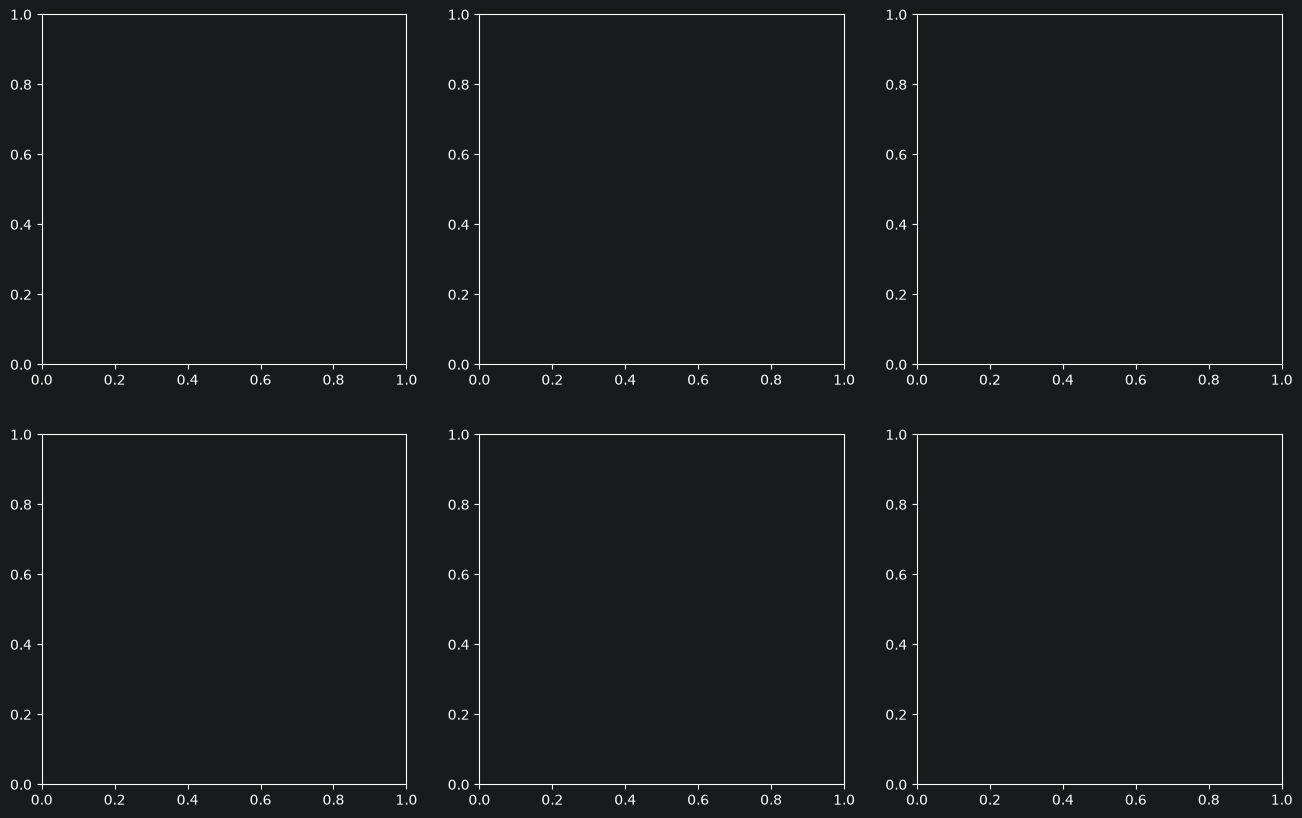

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pilih kolom-kolom numerik yang ingin dicek outlier-nya sekaligus
kolom_numerik = [
    'Pendapatan Keluarga',
    'Pengeluaran Bulanan Keluarga',
    'Cicilan Hutang per Bulan',
    'Luas Tanah Rumah (m2)',
    'Luas Bangunan Rumah (m2)'
]

# 2. Menentukan jumlah baris dan kolom untuk susunan grafik (grid)
# Kita buat grid dengan 2 baris dan 3 kolom (total bisa menampung 6 grafik)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 10))

# 3. Meratakan (flatten) axes agar mudah di-looping
axes = axes.flatten()

# 4. Melakukan looping untuk membuat boxplot di setiap sub-grafik
for i, kolom in enumerate(kolom_numerik):
    # Menggambar boxplot pada objek 'axes' spesifik ke-i
    sns.boxplot(y=X[kolom], ax=axes[i], color='salmon', flierprops={"markerfacecolor":"red", "marker":"o"})

    # Kustomisasi judul dan label tiap sub-grafik
    axes[i].set_title(f'Deteksi Outlier:\n{kolom}', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('') # Menghapus label sumbu Y agar tidak terlalu padat
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

# 5. Menghilangkan grafik kosong jika jumlah kolom lebih sedikit dari slot grid (opsional)
for j in range(len(kolom_numerik), len(axes)):
    fig.delaxes(axes[j])

# 6. Mengatur jarak antar grafik agar tidak tumpang tindih
plt.tight_layout()
plt.show()


In [ ]:
# 1. Mengambil kolom yang jumlah null-nya > 0
kolom_null = train.columns[train.isnull().any()].tolist()

# 2. Tampilkan hasilnya
print(kolom_null)


In [ ]:
import matplotlib.pyplot as plt

plt.style.use('default')

# 1. Filter data: ambil yang nilai null-nya lebih dari 0 dan urutkan
train_null_filtered = train.isnull().sum()
train_null_filtered = train_null_filtered[train_null_filtered > 0].sort_values(ascending=True)

# 2. Membuat visualisasi grafik horizontal
plt.figure(figsize=(12, 8))
bars = plt.barh(train_null_filtered.index, train_null_filtered.values, color='salmon', edgecolor='black')

# 3. Menambahkan label angka di ujung setiap bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + (train_null_filtered.max() * 0.005), bar.get_y() + bar.get_height()/2,
             f'{int(width)}', va='center', ha='left', fontsize=9)

# 4. Kustomisasi diagram
plt.title('Visualisasi Kolom dengan Missing Values (Null > 0)', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Jumlah Missing Values', fontsize=12)
plt.ylabel('Nama Kolom / Fitur', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# 5. Menampilkan grafik
plt.tight_layout()
plt.show()


In [ ]:
train.shape

In [ ]:
X, y = train.drop(columns=["Golongan UKT",'id',"Lokasi Tempat Tinggal", 'Total Hutang', 'Status Kepemilikan Tempat Tinggal' ]), train[['id', 'Golongan UKT']]

#X_train = train.drop(columns=DROP, inplace=False)
#X_train = train.drop(columns=COl_TO_DROP, inplace=False)

In [ ]:
X.shape

In [ ]:
X.info()

In [ ]:
text_cols = X[['Bahan Lantai Rumah', 'Bahan Tembok Rumah', 'Bahan Atap Rumah']]

In [ ]:
!pip install wordcloud


In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 1. Pilih kolom yang ingin dianalisis keberantakannya
kolom_kotor = ['Bahan Atap Rumah', 'Bahan Tembok Rumah', 'Bahan Lantai Rumah']

# 2. Gabungkan semua teks dari ketiga kolom menjadi satu string raksasa
# Fungsi .astype(str) memastikan nilai kosong/NaN diubah jadi teks agar tidak error
teks_gabungan = " ".join(
    X[kolom_kotor].astype(str).stack().tolist()
)

# 3. Membuat objek WordCloud
# collocations=False dimatikan agar kata tunggal bermasalah tidak digabungkan otomatis
wordcloud = WordCloud(
    width=1000,
    height=600,
    background_color='white',
    collocations=False,
    colormap='Set2'
).generate(teks_gabungan)

# 4. Visualisasikan menggunakan Matplotlib
plt.figure(figsize=(15, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Menghilangkan sumbu angka koordinat
plt.title('Word Cloud Keberantakan Data Bahan Atap, Tembok, & Lantai', fontsize=16, fontweight='bold', pad=20)
plt.show()


In [ ]:
train.info()

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 1. Pilih kolom yang ingin dianalisis keberantakannya
kolom_kotor = ['Pendidikan Orang Tua/Wali']

# 2. Gabungkan semua teks dari ketiga kolom menjadi satu string raksasa
# Fungsi .astype(str) memastikan nilai kosong/NaN diubah jadi teks agar tidak error
teks_gabungan = " ".join(
    train[kolom_kotor].astype(str).stack().tolist()
)

# 3. Membuat objek WordCloud
# collocations=False dimatikan agar kata tunggal bermasalah tidak digabungkan otomatis
wordcloud = WordCloud(
    width=1000,
    height=600,
    background_color='white',
    collocations=False,
    colormap='Set2'
).generate(teks_gabungan)

# 4. Visualisasikan menggunakan Matplotlib
plt.figure(figsize=(15, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Menghilangkan sumbu angka koordinat
plt.title('Word Cloud Keberantakan Data Bahan Atap, Tembok, & Lantai', fontsize=16, fontweight='bold', pad=20)
plt.show()


In [17]:
# Ini akan menampilkan semua bahan dan berapa kali bahan itu muncul
print(train['Pendidikan Orang Tua/Wali'].unique())


['SLTA Sederajat' 'SD' 'SLTP' 'MTs' 'MA' 'S-1/D4' 'SLTA' 'S1' 'D-3/D2'
 'SD/MI Sederajat' 'D4' 'SMA' 'S1/D-4' 'SMP' 'MI' 'SLTP Sederajat' nan
 'D3/D-2' 'Tidak Lulus SD' 'S- 2' 'S2 ' 'S-2' 'S-3' 'D.1' 'S- 3' 'D-1'
 'S3 ' ' D1']


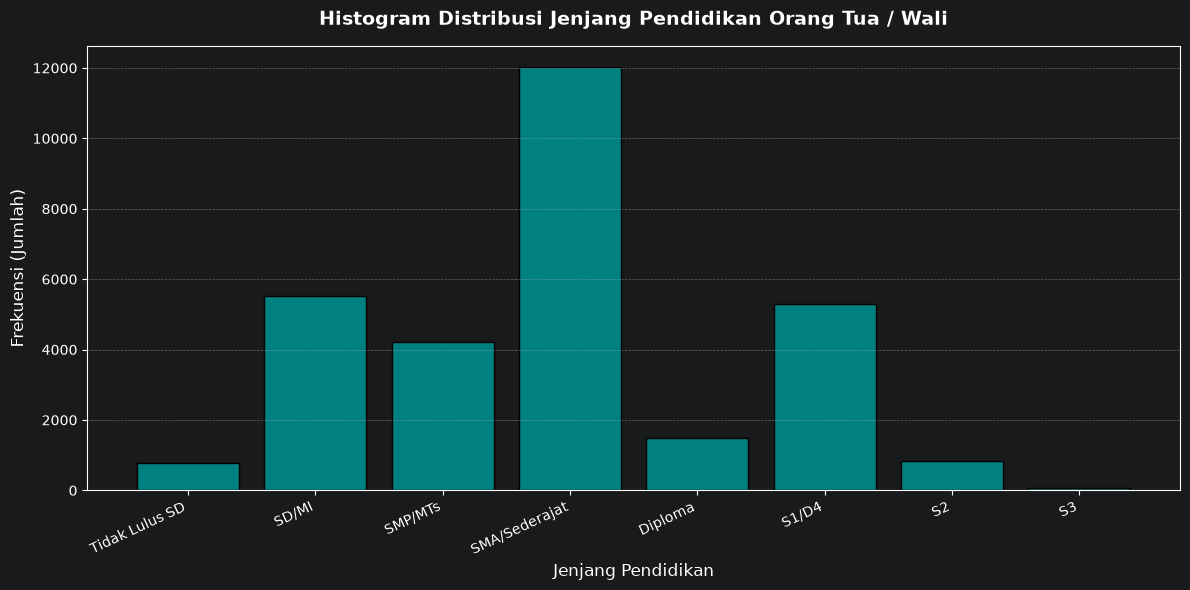

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1. Mengasumsikan kolom di DataFrame X Anda diubah menjadi data mentah (raw data)
# sesuai dengan proporsi distribusi frekuensi yang Anda berikan
raw_data = {
    'SLTA Sederajat': 3067, 'SLTA': 3034, 'SMA': 3004, 'MA': 2929,
    'SD/MI Sederajat': 1846, 'MI': 1836, 'SD': 1829,
    'S1/D-4': 1336, 'S1': 1324, 'S-1/D4': 1322, 'D4': 1301,
    'SMP': 1063, 'MTs': 1059, 'SLTP': 1058, 'SLTP Sederajat': 1034,
    'Tidak Lulus SD': 766, 'D-3/D2': 693, 'D3/D-2': 658,
    'S-2': 292, 'S2': 278, 'S- 2': 273, 'D-1': 45, 'D.1': 40, ' D1': 39,
    'S-3': 22, 'S3': 19, 'S- 3': 13
}

# Membuat list data mentah tiruan agar sesuai dengan kondisi kolom X['Pendidikan Orang Tua/Wali'] Anda
list_pendidikan = []
for k, v in raw_data.items():
    list_pendidikan.extend([k] * v)
X = pd.DataFrame({'Pendidikan Orang Tua/Wali': list_pendidikan})

# =====================================================================
# PROSES ENCODING & VISUALISASI HISTOGRAM
# =====================================================================

# 2. Buat mapping untuk mengubah string berantakan menjadi tingkat angka (0 sampai 7)
kamus_skala = {
    'Tidak Lulus SD': 0,
    'SD': 1, 'MI': 1, 'SD/MI Sederajat': 1,
    'SMP': 2, 'MTs': 2, 'SLTP': 2, 'SLTP Sederajat': 2,
    'SLTA Sederajat': 3, 'SLTA': 3, 'SMA': 3, 'MA': 3,
    'D-1': 4, 'D.1': 4, ' D1': 4, 'D-3/D2': 4, 'D3/D-2': 4,
    'S1/D-4': 5, 'S1': 5, 'S-1/D4': 5, 'D4': 5,
    'S-2': 6, 'S2': 6, 'S- 2': 6,
    'S-3': 7, 'S3': 7, 'S- 3': 7
}

# 3. Simpan hasil transformasi angka ke dalam variabel baru
X['Pendidikan_Numerik'] = X['Pendidikan Orang Tua/Wali'].map(kamus_skala)

# Label untuk sumbu X agar histogram menampilkan teks jenjang pendidikan
label_jenjang = ['Tidak Lulus SD', 'SD/MI', 'SMP/MTs', 'SMA/Sederajat', 'Diploma', 'S1/D4', 'S2', 'S3']

# 4. Membuat Grafik Histogram
plt.figure(figsize=(12, 6))

# Menentukan bin tepat di tengah-tengah angka 0 sampai 7
bins = np.arange(9) - 0.5

# Menggambar histogram
plt.hist(X['Pendidikan_Numerik'], bins=bins, color='teal', edgecolor='black', rwidth=0.8)

# Kustomisasi Sumbu X menggunakan label teks
plt.xticks(range(8), label_jenjang, rotation=25, ha='right')

# Kustomisasi Grafik
plt.title('Histogram Distribusi Jenjang Pendidikan Orang Tua / Wali', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Jenjang Pendidikan', fontsize=12)
plt.ylabel('Frekuensi (Jumlah)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


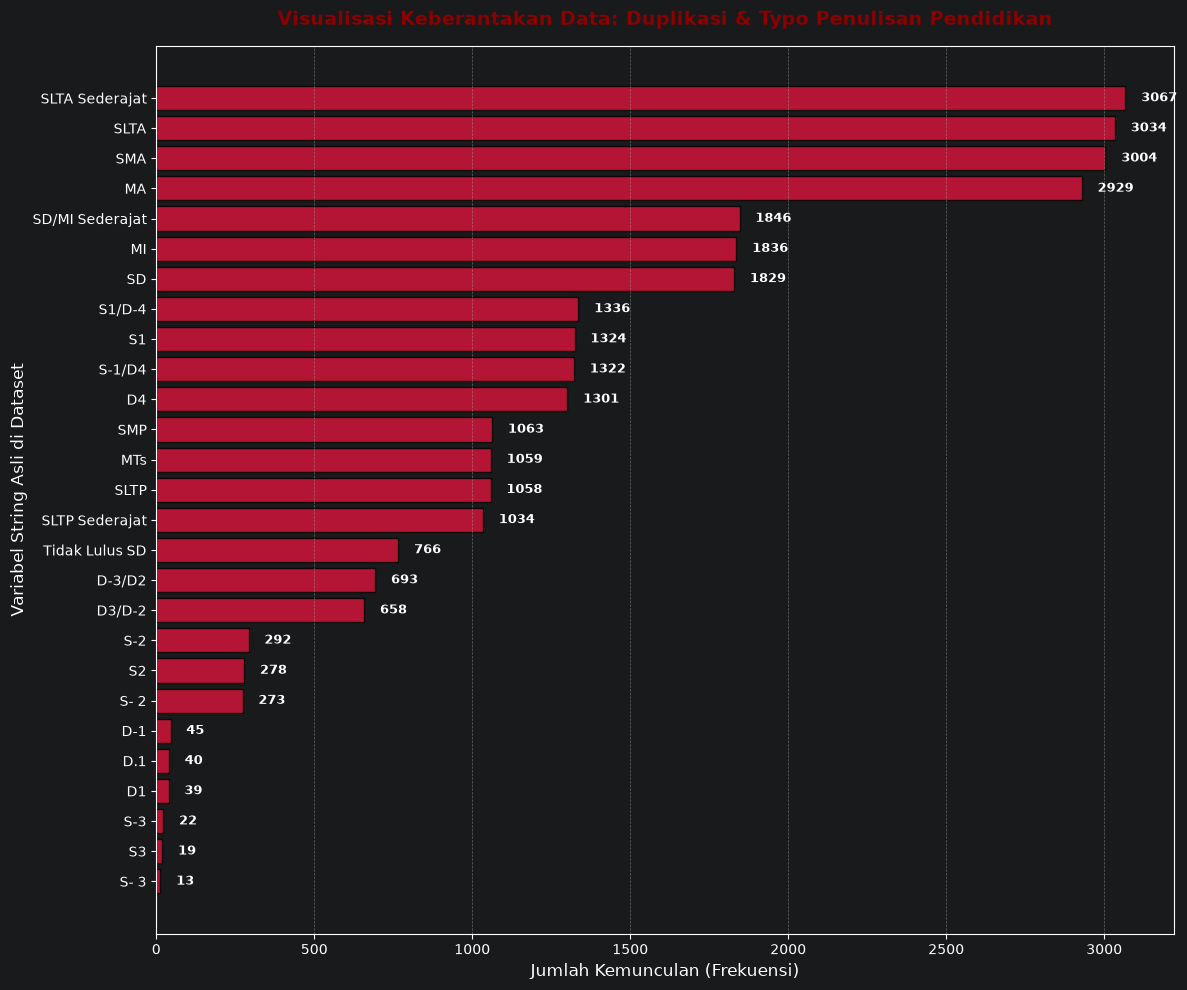

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Menyiapkan data sesuai output value_counts() Anda
data_mentah = {
    'SLTA Sederajat': 3067, 'SLTA': 3034, 'SMA': 3004, 'MA': 2929,
    'SD/MI Sederajat': 1846, 'MI': 1836, 'SD': 1829, 'S1/D-4': 1336,
    'S1': 1324, 'S-1/D4': 1322, 'D4': 1301, 'SMP': 1063, 'MTs': 1059,
    'SLTP': 1058, 'SLTP Sederajat': 1034, 'Tidak Lulus SD': 766,
    'D-3/D2': 693, 'D3/D-2': 658, 'S-2': 292, 'S2': 278, 'S- 2': 273,
    'D-1': 45, 'D.1': 40, ' D1': 39, 'S-3': 22, 'S3': 19, 'S- 3': 13
}

# Mengubahnya menjadi Pandas Series
seri_pendidikan = pd.Series(data_mentah)

# 2. Membuat visualisasi distribusi kategori (Gunakan Horizontal agar teks terbaca jelas)
plt.figure(figsize=(12, 10))

# Menggambar bar plot (representasi histogram untuk data kategori kotor)
bars = plt.barh(seri_pendidikan.index, seri_pendidikan.values, color='crimson', edgecolor='black', alpha=0.8)

# 3. Menambahkan label jumlah di ujung bar
for bar in bars:
    width = bar.get_width()
    plt.text(width + 50, bar.get_y() + bar.get_height()/2, f'{int(width)}',
             va='center', ha='left', fontsize=9, fontweight='bold')

# 4. Kustomisasi untuk mempertegas "Keberantakan Data"
plt.title('Visualisasi Keberantakan Data: Duplikasi & Typo Penulisan Pendidikan',
          fontsize=14, fontweight='bold', color='darkred', pad=15)
plt.xlabel('Jumlah Kemunculan (Frekuensi)', fontsize=12)
plt.ylabel('Variabel String Asli di Dataset', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Membalik urutan sumbu Y agar nilai terbesar berada di paling atas
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


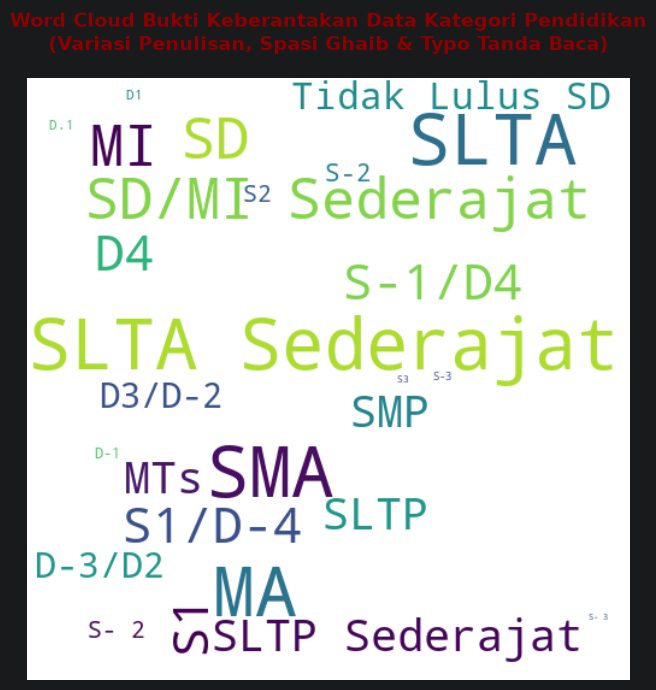

In [19]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 1. Menyiapkan data frekuensi counts sesuai data asli Anda
data_pendidikan = {
    'SLTA Sederajat': 3067, 'SLTA': 3034, 'SMA': 3004, 'MA': 2929,
    'SD/MI Sederajat': 1846, 'MI': 1836, 'SD': 1829, 'S1/D-4': 1336,
    'S1': 1324, 'S-1/D4': 1322, 'D4': 1301, 'SMP': 1063, 'MTs': 1059,
    'SLTP': 1058, 'SLTP Sederajat': 1034, 'Tidak Lulus SD': 766,
    'D-3/D2': 693, 'D3/D-2': 658, 'S-2': 292, 'S2': 278, 'S- 2': 273,
    'D-1': 45, 'D.1': 40, ' D1': 39, 'S-3': 22, 'S3': 19, 'S- 3': 13
}

# 2. Membuat objek WordCloud khusus berdasarkan frekuensi data
# Parameter collocations=False dimatikan agar kata tunggal tidak disatukan otomatis oleh library
wordcloud = WordCloud(
    width=500,
    height=500,
    background_color='white',
    collocations=True,
).generate_from_frequencies(data_pendidikan)

# 3. Visualisasikan menggunakan Matplotlib
plt.figure(figsize=(12, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Menghilangkan garis tepi koordinat angka sumbu

# Judul Visualisasi
plt.title('Word Cloud Bukti Keberantakan Data Kategori Pendidikan\n(Variasi Penulisan, Spasi Ghaib & Typo Tanda Baca)',
          fontsize=14, fontweight='bold', pad=20, color='darkred')

plt.tight_layout()
plt.show()


In [20]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30380 entries, 0 to 30379
Data columns (total 28 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   id                                                      30380 non-null  int64  
 1   Pendapatan Keluarga                                     30168 non-null  object 
 2   Jumlah Tanggungan dalam Keluarga                        30160 non-null  float64
 3   Pekerjaan Orang Tua/Wali                                30186 non-null  object 
 4   Pendidikan Orang Tua/Wali                               30180 non-null  object 
 5   Kepemilikan Aset                                        30173 non-null  object 
 6   Lokasi Tempat Tinggal                                   30237 non-null  object 
 7   Pengeluaran Bulanan Keluarga                            30159 non-null  float64
 8   Status Kepesertaan Program Bantuan P

In [21]:
train['Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki'].unique()

array([2.00e+00, 6.50e+06, 2.00e+07, ..., 3.00e+04, 3.28e+07, 1.03e+07],
      shape=(1136,))

In [22]:
import numpy as np

# Mengatur agar NumPy menampilkan semua elemen array tanpa potongan
np.set_printoptions(threshold=np.inf)

# Cetak kembali nilai uniknya
print(train['Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki'].unique())

# Kembalikan ke pengaturan default setelah selesai (opsional)
np.set_printoptions(threshold=1000)


[2.00000000e+00 6.50000000e+06 2.00000000e+07 8.00000000e+06
 1.00000000e+06 1.60000000e+07 5.00000000e+06 0.00000000e+00
 9.80000000e+07 1.70000000e+07 4.00000000e+06 7.00000000e+06
 9.00000000e+06 1.00000000e+07 8.20000000e+07 1.40000000e+07
 1.42000000e+08 1.00000000e+00 2.60000000e+07 1.80000000e+07
 5.10000000e+07            nan 6.00000000e+06 1.50000000e+07
 1.20000000e+07 2.50000000e+06 2.00000000e+06 8.20000000e+06
 9.70000000e+07 2.40000000e+07 6.25000000e+07 3.10000000e+07
 1.90000000e+07 3.00000000e+07 1.31500000e+08 1.15000000e+08
 4.20000000e+07 1.30000000e+07 7.00000000e+07 1.05000000e+08
 3.50000000e+06 2.30000000e+07 3.00000000e+06 8.00000000e+07
 8.60000000e+07 2.70000000e+07 3.62900000e+07 3.25350000e+07
 5.60000000e+07 1.30000000e+08 1.50000000e+06 1.65000000e+07
 3.23500000e+07 5.90000000e+07 1.00000000e+08 2.74000000e+08
 4.50000000e+06 4.00000000e+07 1.18000000e+08 3.50000000e+07
 1.10000000e+08 8.70000000e+07 2.19000000e+07 1.40000000e+08
 2.10000000e+07 2.190000

In [23]:
print(train['Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki'].head())


0           2.0
1     6500000.0
2    20000000.0
3     8000000.0
4     1000000.0
Name: Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki, dtype: float64


In [58]:
import pandas as pd
with pd.option_context('display.max_rows', None):
    print(X['Bahan Tembok Rumah'].value_counts())


Bahan Tembok Rumah
Batu bata                                             4200
batu bata                                             2758
Batu Bata                                             2044
Semen                                                 1508
Bata                                                  1506
Batako                                                1035
BATU BATA                                             1010
Kayu                                                   834
bata                                                   753
semen                                                  710
Bata merah                                             598
batako                                                 534
kayu                                                   430
bata merah                                             414
Bata Merah                                             372
BATA                                                   314
Batu bata merah                      

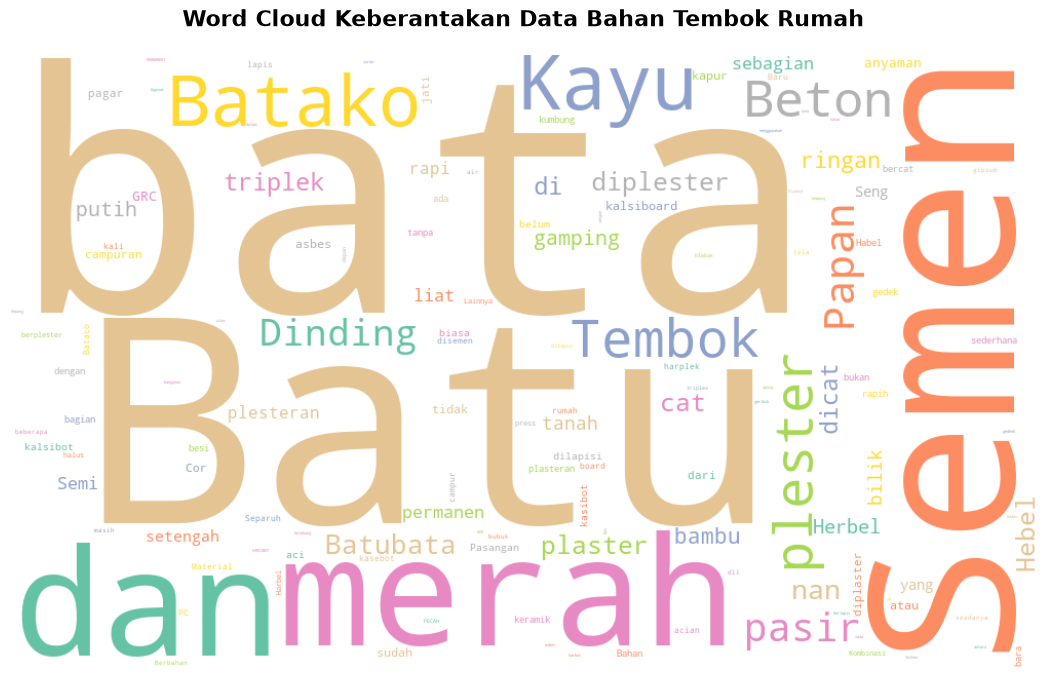

In [49]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# 2. Gabungkan semua teks dari ketiga kolom menjadi satu string raksasa
# Fungsi .astype(str) memastikan nilai kosong/NaN diubah jadi teks agar tidak error
teks_gabungan = " ".join(
    X['Bahan Tembok Rumah'].astype(str).tolist()
)

# 3. Membuat objek WordCloud
# collocations=False dimatikan agar kata tunggal bermasalah tidak digabungkan otomatis
wordcloud = WordCloud(
    width=1000,
    height=600,
    background_color='white',
    collocations=False,
    colormap='Set2'
).generate(teks_gabungan)

# 4. Visualisasikan menggunakan Matplotlib
plt.figure(figsize=(15, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')  # Menghilangkan sumbu angka koordinat
plt.title('Word Cloud Keberantakan Data Bahan Tembok Rumah', fontsize=16, fontweight='bold', pad=20)
plt.show()


In [498]:
cat_col = list(set(X.columns[X.dtypes == object].tolist() + X.iloc[:, 22:].columns.tolist()))
num_cols = list(set(X.columns.tolist()) - set(cat_col))

In [499]:
X_impute = X.copy()
X_impute[cat_col].fillna("Yang lain", inplace=True)
X_impute.fillna(-1, inplace=True)

C:\Users\hajar\AppData\Local\Temp\ipykernel_38812\478121888.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_impute[cat_col].fillna("Yang lain", inplace=True)


In [500]:
X_impute.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30380 entries, 0 to 30379
Data columns (total 23 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   Pendapatan Keluarga                                     30380 non-null  object 
 1   Jumlah Tanggungan dalam Keluarga                        30380 non-null  float64
 2   Pekerjaan Orang Tua/Wali                                30380 non-null  object 
 3   Pendidikan Orang Tua/Wali                               30380 non-null  object 
 4   Kepemilikan Aset                                        30380 non-null  object 
 5   Pengeluaran Bulanan Keluarga                            30380 non-null  float64
 6   Status Kepesertaan Program Bantuan Pemerintah           30380 non-null  object 
 7   Riwayat Beasiswa atau Bantuan Pendidikan                30380 non-null  object 
 8   Ayah Hidup?                         

In [501]:
autogluon_dfx = TabularDataset(X_impute)
autogluon_dfx.head()

,Pendapatan Keluarga,Jumlah Tanggungan dalam Keluarga,Pekerjaan Orang Tua/Wali,Pendidikan Orang Tua/Wali,Kepemilikan Aset,Pengeluaran Bulanan Keluarga,Status Kepesertaan Program Bantuan Pemerintah,Riwayat Beasiswa atau Bantuan Pendidikan,Ayah Hidup?,Ibu Hidup?,...,Luas Bangunan Rumah (m2),NJOP per Meter,Bahan Atap Rumah,Bahan Tembok Rumah,Bahan Lantai Rumah,Rerata Pengeluaran Listrik & Air per Bulan,Cicilan Hutang per Bulan,Program Studi,Kota,Jalur Masuk
0,Rp 1.000.000 s.d. Rp 2.000.000,2.0,Tidak Bekerja,SLTA Sederajat,Milik Sendiri,500000.0,KIS/JKS/BPJS,KIPK,Meninggal,Hidup,...,126.0,103.0,genting,semen,keramik,450000.0,0.0,Ilmu Politik,Kab. Sragen,SNBT
1,lebih dari Rp 5.000.000,2.0,Buruh,SLTA Sederajat,Milik Sendiri,3500000.0,KIS/JKS/BPJS,Tidak Ada,Hidup,Hidup,...,22.0,128.0,Genteng,Batako Plester,Keramik,320000.0,4500000.0,Geografi,Kabupaten Tangerang,SNBP
2,Rp 3.000.000 s.d. Rp 4.000.000,2.0,Wiraswasta,SD,Milik Sendiri,600000.0,KIS/JKS/BPJS,Tidak,Hidup,Hidup,...,65.0,128000.0,Genting,Batu Bata,Keramik,-1.0,0.0,Ilmu Politik,Kabupaten Grobogan,SNBT
3,lebih dari Rp 5.000.000,2.0,Wiraswasta,SLTP,Milik Sendiri,2250000.0,KIS/JKS/BPJS,Tidak Dapat,Hidup,Hidup,...,70.0,2176000.0,Kayu dan asbes,Bata merah dan hebel,Keramik,500000.0,0.0,Pendidikan Ekonomi,Kab. Bogor,SNBT
4,Rp 3.000.000 s.d. Rp 4.000.000,-1.0,Wiraswasta,MTs,Milik Sendiri,2310000.0,KIS/JKS/BPJS,Tidak Dapat,Hidup,Hidup,...,57.0,0.0,"Genting tanah liat, asbes, dan seng.",Batu bata,"Keramik, tegel, plester.",105000.0,500000.0,Pendidikan Teknik Elektro,Kabupaten Pemalang,SNBP


In [502]:
auto_ml_pipeline_feature_generator = AutoMLPipelineFeatureGenerator()
X_gluon = auto_ml_pipeline_feature_generator.fit_transform(X=autogluon_dfx)
X_gluon.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30380 entries, 0 to 30379
Data columns (total 78 columns):
 #   Column                                                  Non-Null Count  Dtype   
---  ------                                                  --------------  -----   
 0   Jumlah Tanggungan dalam Keluarga                        30380 non-null  float64 
 1   Pengeluaran Bulanan Keluarga                            30380 non-null  float64 
 2   Status Kepesertaan Program Bantuan Pemerintah           30380 non-null  int8    
 3   Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki  30380 non-null  float64 
 4   Daya Listrik (Watt)                                     30380 non-null  float64 
 5   Luas Tanah Rumah (m2)                                   30380 non-null  float64 
 6   Luas Bangunan Rumah (m2)                                30380 non-null  float64 
 7   NJOP per Meter                                          30380 non-null  float64 
 8   Rerata Pengeluaran Listrik

In [503]:
train_df = auto_ml_pipeline_feature_generator.transform(X=autogluon_dfx)

In [504]:
list(set(X_impute.columns) - set(X_gluon.columns))

[]

In [505]:
X_gluon.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30380 entries, 0 to 30379
Data columns (total 78 columns):
 #   Column                                                  Non-Null Count  Dtype   
---  ------                                                  --------------  -----   
 0   Jumlah Tanggungan dalam Keluarga                        30380 non-null  float64 
 1   Pengeluaran Bulanan Keluarga                            30380 non-null  float64 
 2   Status Kepesertaan Program Bantuan Pemerintah           30380 non-null  int8    
 3   Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki  30380 non-null  float64 
 4   Daya Listrik (Watt)                                     30380 non-null  float64 
 5   Luas Tanah Rumah (m2)                                   30380 non-null  float64 
 6   Luas Bangunan Rumah (m2)                                30380 non-null  float64 
 7   NJOP per Meter                                          30380 non-null  float64 
 8   Rerata Pengeluaran Listrik

In [506]:
train_df = auto_ml_pipeline_feature_generator.transform(X=autogluon_dfx)

In [507]:
list(set(X_impute.columns) - set(X_gluon.columns))

[]

In [508]:
gluon_cat_cols = X_gluon.columns[X_gluon.dtypes == "category"].tolist()
gluon_cat_cols

['Pendapatan Keluarga',
 'Pekerjaan Orang Tua/Wali',
 'Pendidikan Orang Tua/Wali',
 'Kepemilikan Aset',
 'Riwayat Beasiswa atau Bantuan Pendidikan',
 'Ayah Hidup?',
 'Ibu Hidup?',
 'Bahan Atap Rumah',
 'Bahan Tembok Rumah',
 'Bahan Lantai Rumah',
 'Program Studi',
 'Kota',
 'Jalur Masuk']

In [509]:
print(X_gluon.isnull().sum())

Jumlah Tanggungan dalam Keluarga                          0
Pengeluaran Bulanan Keluarga                              0
Status Kepesertaan Program Bantuan Pemerintah             0
Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki    0
Daya Listrik (Watt)                                       0
                                                         ..
__nlp__.semen dan batu                                    0
__nlp__.semen pasir                                       0
__nlp__.tembok                                            0
__nlp__.triplek                                           0
__nlp__._total_                                           0
Length: 78, dtype: int64


In [510]:
X_gluon[gluon_cat_cols] = X_gluon[gluon_cat_cols].astype(str)
X_gluon[gluon_cat_cols].fillna("Tidak ada", inplace=True)

C:\Users\hajar\AppData\Local\Temp\ipykernel_38812\3304013839.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_gluon[gluon_cat_cols].fillna("Tidak ada", inplace=True)


In [511]:
train.shape

(30380, 28)

In [512]:
X_gluon.shape

(30380, 78)

In [513]:
X_gluon.head()

,Jumlah Tanggungan dalam Keluarga,Pengeluaran Bulanan Keluarga,Status Kepesertaan Program Bantuan Pemerintah,Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki,Daya Listrik (Watt),Luas Tanah Rumah (m2),Luas Bangunan Rumah (m2),NJOP per Meter,Rerata Pengeluaran Listrik & Air per Bulan,Cicilan Hutang per Bulan,...,__nlp__.ringan,__nlp__.semen,__nlp__.semen batu,__nlp__.semen beton,__nlp__.semen dan,__nlp__.semen dan batu,__nlp__.semen pasir,__nlp__.tembok,__nlp__.triplek,__nlp__._total_
0,2.0,500000.0,0,2.0,900.0,144.0,126.0,103.0,450000.0,0.0,...,0,1,0,0,0,0,0,0,0,1
1,2.0,3500000.0,0,6500000.0,900.0,60.0,22.0,128.0,320000.0,4500000.0,...,0,0,0,0,0,0,0,0,0,2
2,2.0,600000.0,0,20000000.0,450.0,586.0,65.0,128000.0,-1.0,0.0,...,0,0,0,0,0,0,0,0,0,3
3,2.0,2250000.0,0,8000000.0,900.0,93.0,70.0,2176000.0,500000.0,0.0,...,0,0,0,0,0,0,0,0,0,5
4,-1.0,2310000.0,0,1000000.0,900.0,0.0,57.0,0.0,105000.0,500000.0,...,0,0,0,0,0,0,0,0,0,3


In [514]:
X_gluon.isnull().sum()

Jumlah Tanggungan dalam Keluarga                          0
Pengeluaran Bulanan Keluarga                              0
Status Kepesertaan Program Bantuan Pemerintah             0
Jumlah (Perkiraan Harga Pasar) Kendaraan yang Dimiliki    0
Daya Listrik (Watt)                                       0
                                                         ..
__nlp__.semen dan batu                                    0
__nlp__.semen pasir                                       0
__nlp__.tembok                                            0
__nlp__.triplek                                           0
__nlp__._total_                                           0
Length: 78, dtype: int64

In [515]:
df_full = pd.concat([X_gluon, y], axis=1)


In [516]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

lgb_params = {
    "objective": "binary",
    "metric": "auc",
    "boosting_type": "gbdt",
    "learning_rate": 0.05,
    "num_leaves": 31,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "random_state": SEED,
    "verbose": -1,
}

In [522]:
from sklearn.model_selection import train_test_split
import numpy as np

df_train, df_test = train_test_split(df_full, test_size=0.5, random_state=SEED)

y_full = df_train['Golongan UKT']


In [523]:
X_train_full, X_val_full, y_train_full, y_val_full = train_test_split(df_train, y_full,test_size=0.2, random_state=SEED)

In [524]:
oof_preds = np.zeros(len(X_train_full))
test_preds = np.zeros(len(X_test_full))
fold_scores = []

11964    4.0
28463    4.0
16743    5.0
30113    0.0
5882     4.0
        ... 
20909    7.0
26634    0.0
368      0.0
4636     3.0
27572    4.0
Name: Golongan UKT, Length: 12152, dtype: float64

In [530]:
import time

# Train models
def multiclass_oof_preds(
    classifier,
    model_key,
    X_train,
    y_train,
    X_test,
    metric_score,
    metric_score_args={},
    model_args={},
    fitting_args={},
    n_folds=5,
    dir_name="output",
    verbose=False,
):
    # if X_test != None:
    test_preds = np.zeros((len(X_test), y_train.nunique()))
    # else:
    #     test_preds = np.array([])
    oof_full = np.zeros((len(y_train), y_train.nunique()))
    is_target_str = y_train.dtype == "object"

    # Start timer
    start = time.time()

    # k-fold cross validation
    cv = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=0)

    score = 0
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train)):
        # Get training and validation sets
        x_tr, x_valid = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_valid = y_train.iloc[train_idx], y_train.iloc[val_idx]

        # Start timer
        start = time.time()

        # # Tune hyperparameters
        # clf = RandomizedSearchCV(estimator=classifier, \
        #                          param_distributions=grid[model_key], \
        #                          n_iter=20, scoring='average_precision', n_jobs=-1, cv=5)

        # Train using PredefinedSplit
        clf = classifier(
            **model_args
        )
        clf.fit(x_tr, y_tr,
                # sample_weight=sample_weights[train_idx],
                **fitting_args)

        # Out-of-fold predictions
        oof_preds = clf.predict_proba(x_valid)
        if is_target_str:
            score += (
                metric_score(
                    y_valid.tolist(),
                    [clf.classes_[i] for i in np.argmax(oof_preds, axis=1)],
                    **metric_score_args,
                )
                / n_folds
            )
        else:
            score += (
                metric_score(y_valid, np.argmax(oof_preds, axis=1), **metric_score_args)
                / n_folds
            )
        oof_full[val_idx] = oof_preds

        # if X_test != None:
            # Test set predictions
        test_preds += clf.predict_proba(X_test) / n_folds

    # Stop timer
    stop = time.time()

    if verbose:
        # Print score and time
        print("Model:", model_key)
        print("Average Metric:", np.round(100 * score, 2))
        print("Training time (mins):", np.round((stop - start) / 60, 2))
        print("")

    # Save oof and test set preds
    with open(f"{dir_name}/{model_key}_oof_preds.pkl", "wb") as f:
        pkl.dump(oof_full, f)
    # ss.to_csv(f"{dir_name}/{model_key}_test_preds.csv", index=False)
    # if X_test != None:
    with open(f"{dir_name}/{model_key}_test_preds.pkl", "wb") as f:
        pkl.dump(test_preds, f)

    return score, oof_full, test_preds

In [531]:
import lightgbm as lgb
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix,
)
from sklearn.metrics import f1_score
n_folds = 5


# Train CatBoost model
cb_score, cb_oof, cb_test = multiclass_oof_preds(
    CatBoostClassifier,
    "CatBoost",
    X_gluon,
    y,
    test_df,
    metric_score=f1_score,
    metric_score_args={"average": "macro"},
    model_args={
        "loss_function": "MultiClass",
        "eval_metric": "TotalF1",
        # "max_bin": 254,
        "task_type": "GPU",
        "devices": "0",
        "verbose": 200,
        "random_state": 42,
        # "cat_features": cat_cols,
        # "text_features": text_cols,
        # "class_weights": class_weights_dict,
    },
    n_folds=n_folds,
    dir_name=dir_name,
    verbose=True,
)

baseline.fit(X_train_full, y_train_full)      #Latih model baseline

valid_pred = baseline.predict(X_val_full)  #Untuk uji validasi model paai data X_valid

print("Accuracy:", round(accuracy_score(y_val_full, valid_pred), 4))
print("Macro-F1:", round(f1_score(
    y_val_full, valid_pred, average="macro"
), 4))

print("\nClassification report:")
print(classification_report(y_val_full, valid_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(
    y_val_full,
    valid_pred,
    labels=baseline.classes_,
))
print("Urutan kelas:", baseline.classes_)

NameError: name 'test_df' is not defined